# Land carbon and water fluxes per contrast category

Vegetation responses that the radiative notebooks do not show: **GPP, respiration, net CO₂ exchange, carbon stocks** and the **split of evapotranspiration**.
Plotting: `forcing_maps.make_contrast_grid_figure` (same maps, hatching = NOT significant, paired yearly t-test + FDR α = 0.10, column scales as in the other notebooks). The extra yearly fields are registered **in this notebook only** (`fm.YEARLY_DERIVED`), `src/` is not changed.

**Outputs** (as the other analysis notebooks): `results/figures/<category>/contrast_grid_{carbon,et_split}_<category>_<years>.png`, `results/figures/interactive/seasonal_cycle_carbon_et_modified_<years>.png`, `results/tables/land_carbon_water_regional_<years>.csv`, `results/tables/seasonal_cycle_lcc_minus_ctrl_modified_<years>.csv`.

**Inputs:** processed CLM files `<ALIAS>_lnd_{BIOGEOCHEM,ET,LAND}_2001-2025.nc` (monthly, spin-up year 2000 dropped). Contrasts: `fm.CONTRASTS` (4 categories). `LCC_FUT_fBVOClccFUT` = design-B stand-in.

**Signs and units:**

| Field | Meaning | Sign |
|---|---|---|
| GPP | gross photosynthetic uptake | + = uptake |
| AR | autotrophic (plant) respiration = CO₂ released by the vegetation | + = release |
| HR | heterotrophic (soil/litter) respiration | + = release |
| NPP = GPP − AR | | + = uptake |
| NEE | net ecosystem exchange, incl. fire | **+ = CO₂ to the atmosphere** |
| NBP | net biome production (incl. fire, land use, harvest) | + = land sink |

Fluxes in gC m⁻² yr⁻¹ (×365 d, noleap), stocks in kgC m⁻², water in mm day⁻¹.

**Caveat (b):** CO₂ is prescribed in CAM (`NF` compsets), so these land CO₂ fluxes do **not** feed back on atmospheric CO₂ or radiation in the runs. They are diagnostics; turning them into a forcing needs an offline step.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # repo src/, no pip install needed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.plotting import palette as pal

set_default_style()
START_YEAR, END_YEAR = 2001, 2025
# Outputs go to results/ like the other analysis notebooks: figures/<category>/, tables/ (cross-category)
FIGDIR, TABDIR = fm.FIGURE_DIR, fm.TABLE_DIR
TABDIR.mkdir(parents=True, exist_ok=True)
SPY = fm.SECONDS_PER_YEAR   # 365 d (noleap)

# Extra yearly fields (this notebook only): gC m-2 s-1 -> gC m-2 yr-1, gC m-2 -> kgC m-2, mm s-1 -> mm day-1
for v in ("GPP", "NPP", "AR", "HR", "ER", "NEE", "NBP"):
    fm.YEARLY_DERIVED[f"{v}_gm2yr"] = (lambda v: lambda ds, mo: fm.annual_mean(ds[v], ds, mo) * SPY)(v)
for v in ("TOTVEGC", "TOTSOMC", "TOTECOSYSC"):
    fm.YEARLY_DERIVED[f"{v}_kgm2"] = (lambda v: lambda ds, mo: fm.annual_mean(ds[v], ds, mo) * 1e-3)(v)
for v in ("QVEGT", "QVEGE", "QSOIL"):
    fm.YEARLY_DERIVED[f"{v}_mmday"] = (lambda v: lambda ds, mo: fm.annual_mean(ds[v], ds, mo) * 86400)(v)

GYR, KGM2, MMDAY = "gC m$^{-2}$ yr$^{-1}$", "kgC m$^{-2}$", fm.MMDAY
P = lambda key, title, cls, var, units, label: fm._panel(key, title, cls, var, units, label, "lnd")
CARBON_PANELS = [
    P("gpp", "GROSS PRIMARY PRODUCTION", "BIOGEOCHEM", "GPP_gm2yr", GYR, "GPP (uptake)"),
    P("npp", "NET PRIMARY PRODUCTION", "BIOGEOCHEM", "NPP_gm2yr", GYR, "NPP = GPP − AR"),
    P("ar", "PLANT RESPIRATION", "BIOGEOCHEM", "AR_gm2yr", GYR, "AR (CO$_2$ from vegetation)"),
    P("hr", "SOIL RESPIRATION", "BIOGEOCHEM", "HR_gm2yr", GYR, "HR (heterotrophic)"),
    P("nee", "NET CO$_2$ TO ATMOSPHERE", "BIOGEOCHEM", "NEE_gm2yr", GYR, "NEE (+ = source)"),
    P("totvegc", "VEGETATION CARBON", "BIOGEOCHEM", "TOTVEGC_kgm2", KGM2, "TOTVEGC"),
    P("totecosysc", "ECOSYSTEM CARBON", "BIOGEOCHEM", "TOTECOSYSC_kgm2", KGM2, "TOTECOSYSC"),
]
ET_PANELS = [
    P("et", "EVAPOTRANSPIRATION", "ET", "QFLX_mmday", MMDAY, "QFLX_EVAP_TOT"),
    P("qvegt", "TRANSPIRATION", "ET", "QVEGT_mmday", MMDAY, "QVEGT"),
    P("qvege", "CANOPY EVAPORATION", "ET", "QVEGE_mmday", MMDAY, "QVEGE (interception)"),
    P("qsoil", "GROUND EVAPORATION", "ET", "QSOIL_mmday", MMDAY, "QSOIL (soil/snow − dew)"),
    P("tlai", "LEAF AREA INDEX", "LAND", "TLAI", "m$^2$ m$^{-2}$", "TLAI"),
]

for alias in fm.category_aliases():
    ok = all(fm.filename(alias, c, START_YEAR, END_YEAR, "lnd").exists() for c in ("BIOGEOCHEM", "ET", "LAND"))
    print(f"{alias:24s}", "✓" if ok else "MISSING")

CTRL_FUT                 ✓
CTRL_FUT_fBVOCctrlFUT    ✓
CTRL_PD                  ✓
CTRL_PD_fBVOCctrlPD      ✓
LCC_FUT                  ✓
LCC_FUT_fBVOCctrlFUT     ✓
LCC_FUT_fBVOCctrlPD      ✓
LCC_FUT_fBVOClccFUT      ✓
LCC_FUT_fBVOClccPD       ✓
LCC_PD                   ✓
LCC_PD_fBVOCctrlPD       ✓
LCC_PD_fBVOClccPD        ✓


## 1. Carbon fluxes and stocks
GPP, NPP, plant (AR) and soil (HR) respiration, net CO₂ flux to the atmosphere (NEE), vegetation and ecosystem carbon. Number under each map = land mean 45–90°N ± 95 % CI over the 25 yearly differences.

findfont: Failed to find font weight semibold, now using 700.
findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/interactive/contrast_grid_carbon_interactive_2001_2025.png


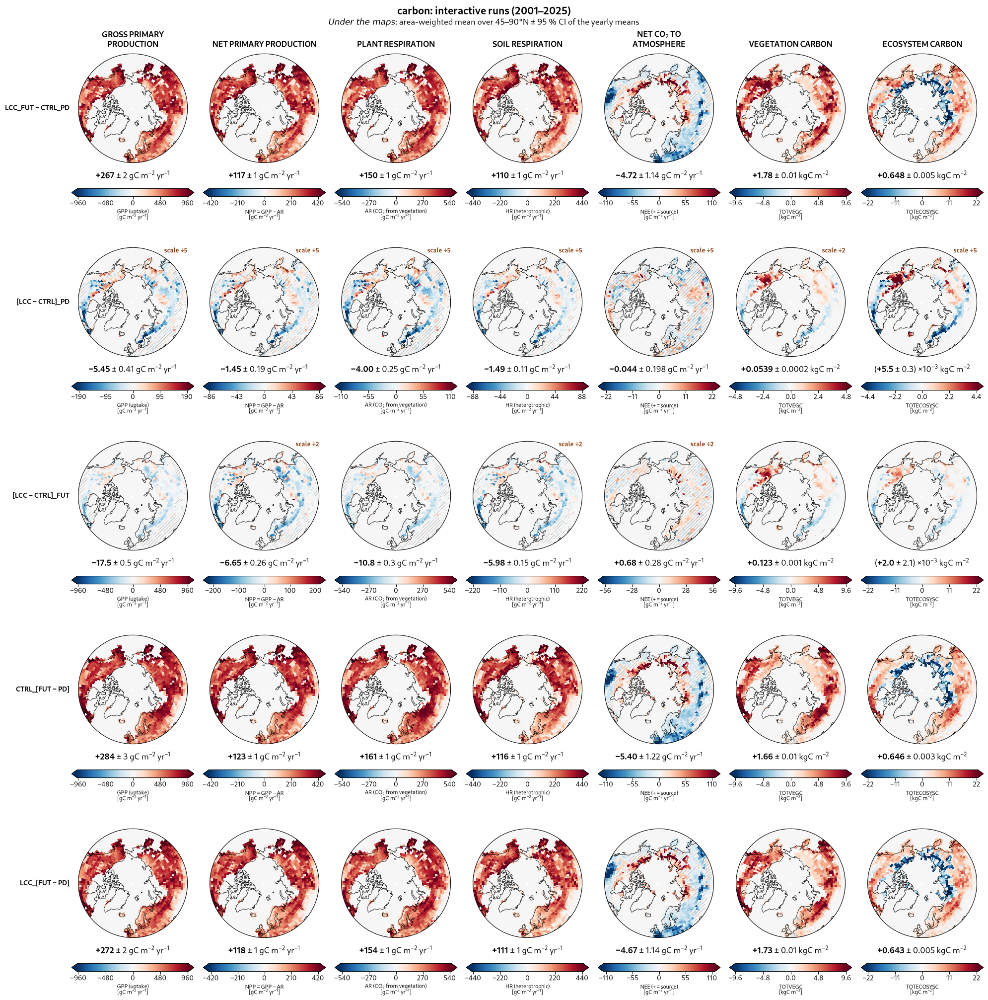

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/fBVOC/contrast_grid_carbon_fBVOC_2001_2025.png


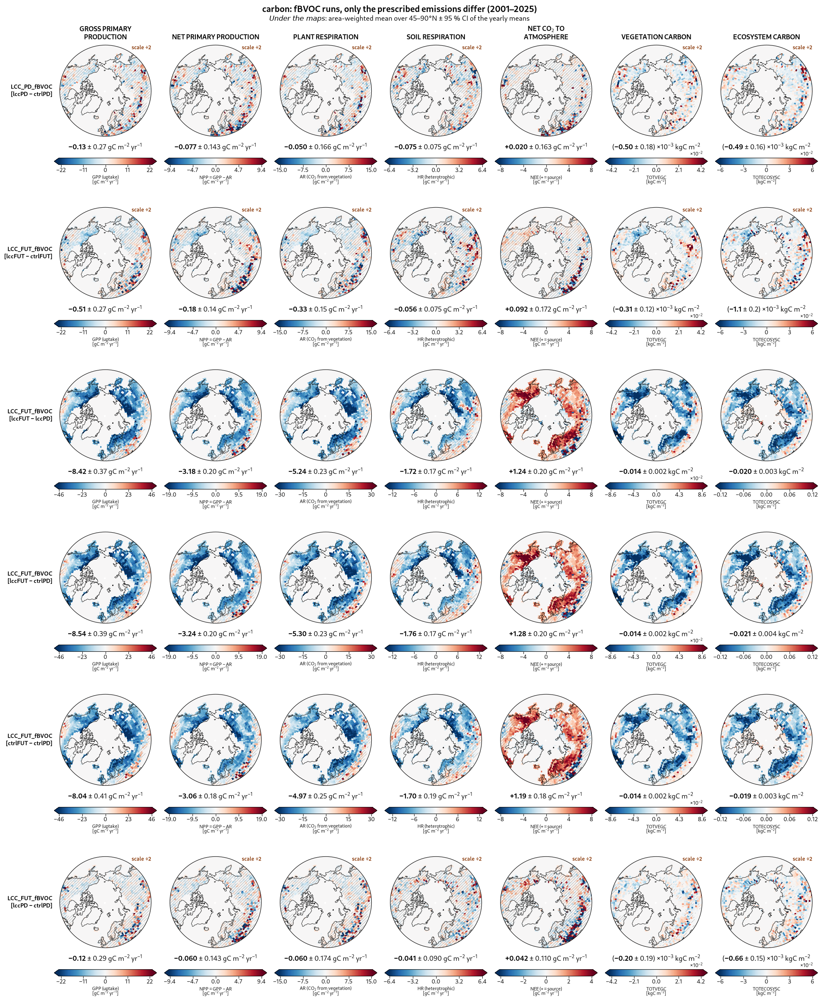

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/non-BVOC/contrast_grid_carbon_non-BVOC_2001_2025.png


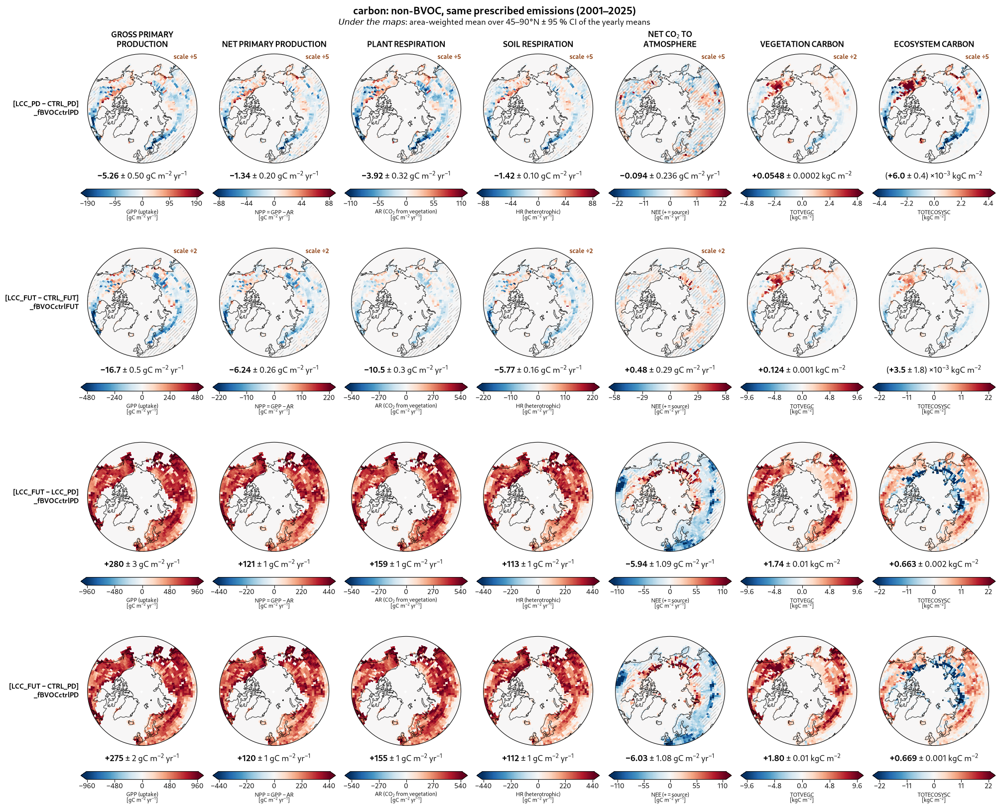

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefacts/contrast_grid_carbon_artefacts_2001_2025.png


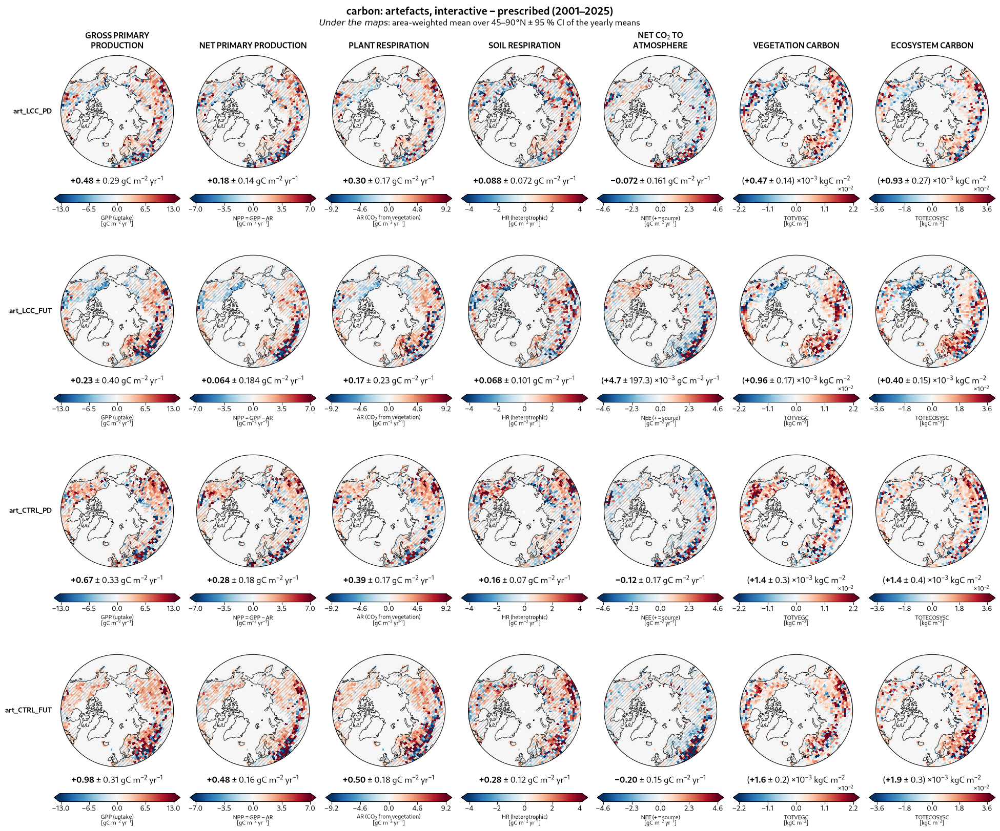

In [2]:
for cat in fm.CATEGORIES:
    fig, axes = fm.make_contrast_grid_figure(cat, CARBON_PANELS, "carbon", start_year=START_YEAR, end_year=END_YEAR,
                                             figdir=FIGDIR / cat)
    plt.show(); plt.close(fig)

## 2. Evapotranspiration split
ET = transpiration + canopy evaporation + ground evaporation (QFLX_EVAP_TOT = QVEGT + QVEGE + QSOIL), with LAI for reference. Total ET is also in the hydro grid of `biogeophysical-hydro.ipynb`.

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/interactive/contrast_grid_et_split_interactive_2001_2025.png


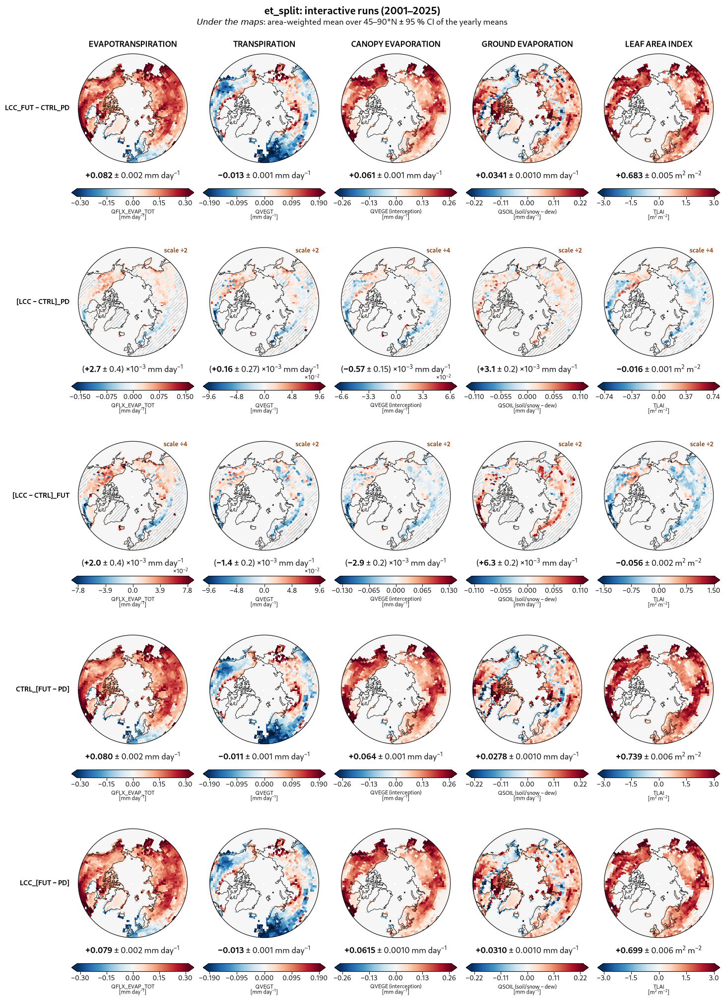

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/fBVOC/contrast_grid_et_split_fBVOC_2001_2025.png


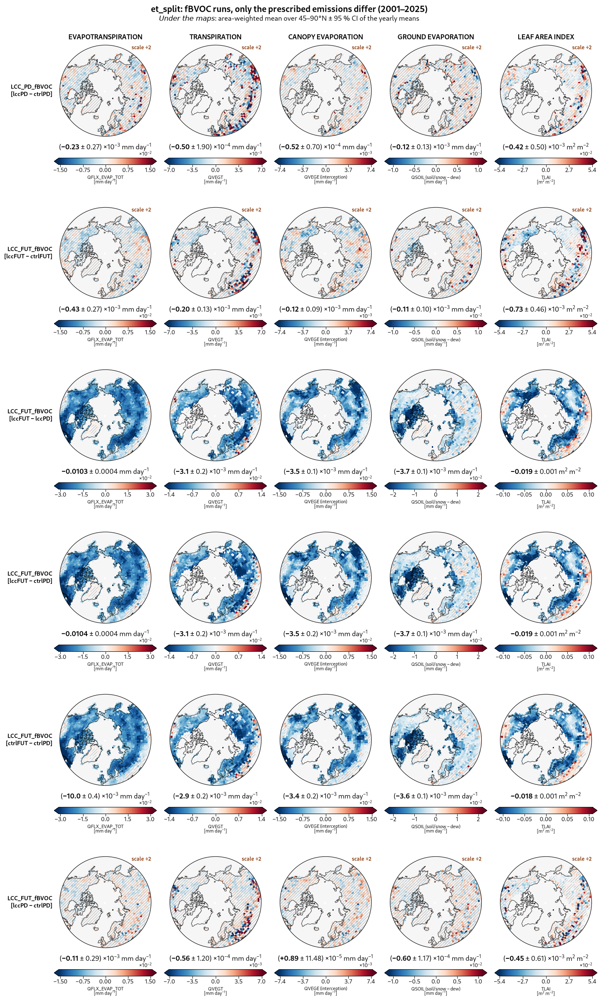

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/non-BVOC/contrast_grid_et_split_non-BVOC_2001_2025.png


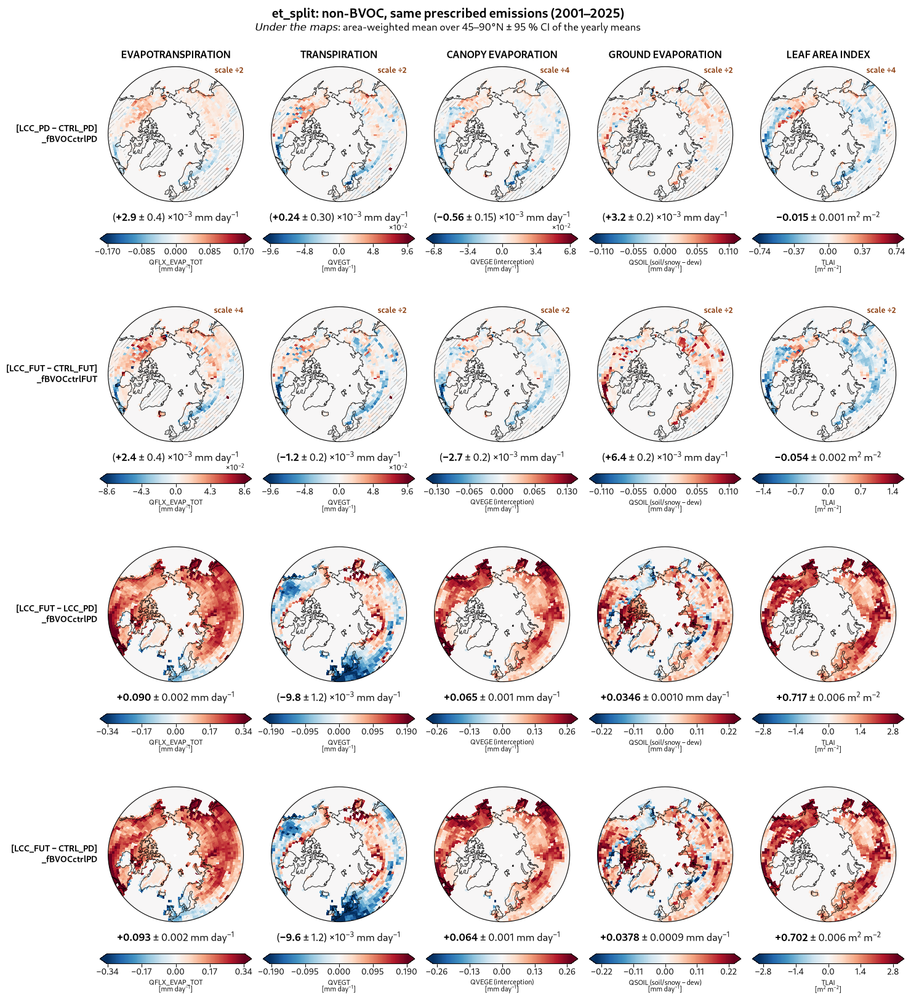

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefacts/contrast_grid_et_split_artefacts_2001_2025.png


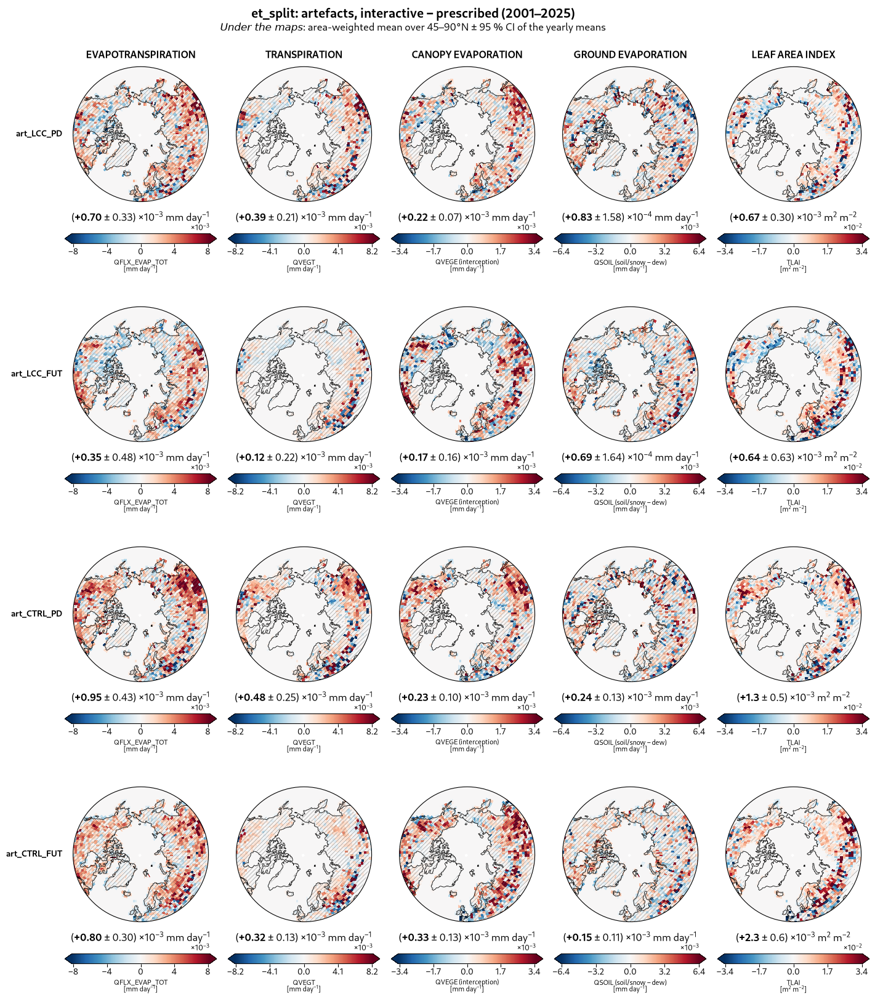

In [3]:
for cat in fm.CATEGORIES:
    fig, axes = fm.make_contrast_grid_figure(cat, ET_PANELS, "et_split", start_year=START_YEAR, end_year=END_YEAR,
                                             figdir=FIGDIR / cat)
    plt.show(); plt.close(fig)

## 3. Regional totals
Regions as in the water budget (`fm.water_budget_regions`): LCC-modified cells and unmodified land ≥45°N. Weights = cell area × landfrac.
Carbon fluxes = **regional totals in TgC yr⁻¹**, stocks in **PgC**, water = **area-mean mm yr⁻¹**. Difference = mean of the yearly paired differences ± 95 % t-interval (n = 25).

In [4]:
# term: (category, variable, kind)  kind: flux -> TgC/yr total, stock -> PgC total, water -> mm/yr mean
TERMS = {"GPP": ("BIOGEOCHEM", "GPP", "flux"), "NPP": ("BIOGEOCHEM", "NPP", "flux"),
         "AR": ("BIOGEOCHEM", "AR", "flux"), "HR": ("BIOGEOCHEM", "HR", "flux"),
         "NEE": ("BIOGEOCHEM", "NEE", "flux"), "NBP": ("BIOGEOCHEM", "NBP", "flux"),
         "TOTVEGC": ("BIOGEOCHEM", "TOTVEGC", "stock"), "TOTECOSYSC": ("BIOGEOCHEM", "TOTECOSYSC", "stock"),
         "ET": ("ET", "QFLX_EVAP_TOT", "water"), "QVEGT": ("ET", "QVEGT", "water"),
         "QVEGE": ("ET", "QVEGE", "water"), "QSOIL": ("ET", "QSOIL", "water")}
UNIT = {"flux": "TgC/yr", "stock": "PgC", "water": "mm/yr"}

ref = fm.open_class(fm.category_aliases()[0], "BIOGEOCHEM", START_YEAR, END_YEAR, "lnd")
REGIONS = fm.water_budget_regions(ref)
W = (ref["area"] * 1e6 * ref["landfrac"]).fillna(0.0)   # m2 of land

def regional_series(alias):
    """{(region, term): yearly series} of one real run."""
    out, cache = {}, {}
    for term, (cls, var, kind) in TERMS.items():
        ds = cache.setdefault(cls, fm.open_class(alias, cls, START_YEAR, END_YEAR, "lnd"))
        y = fm.annual_mean(ds[var], ds)
        for rname, mask in REGIONS.items():
            w = W.where(mask, 0.0)
            if kind == "water":
                out[rname, term] = y.weighted(w).mean(("lat", "lon")) * SPY
            else:
                tot = (y.fillna(0.0) * w).sum(("lat", "lon"))   # gC/s or gC
                out[rname, term] = tot * SPY / 1e12 if kind == "flux" else tot / 1e15
    return out

SERIES = {a: regional_series(a) for a in fm.category_aliases()}
run_val = lambda run, key: sum(k * SERIES[a][key] for a, k in fm.run_weights(run).items())

rows = []
for cat, contrasts in fm.CONTRASTS.items():
    for c in contrasts:
        for key in SERIES[fm.category_aliases()[0]]:
            a, b = run_val(c.case1, key), run_val(c.case2, key)
            d = (a - b).values
            half = stats.t.ppf(0.975, d.size - 1) * d.std(ddof=1) / np.sqrt(d.size)
            rows.append(dict(category=cat, contrast=c.one_line, region=key[0], term=key[1],
                             units=UNIT[TERMS[key[1]][2]], case1=float(a.mean()), case2=float(b.mean()),
                             diff=float(d.mean()), ci95=float(half), n_years=d.size))
table = pd.DataFrame(rows)
path = TABDIR / f"land_carbon_water_regional_{START_YEAR}_{END_YEAR}.csv"
table.to_csv(path, index=False)
print("Saved", path)

# Compact view: difference ± CI, interactive category, modified cells
pd.set_option("display.width", 250, "display.max_columns", 20)
for cat in fm.CATEGORIES:
    t = table[(table.category == cat) & (table.region == "modified cells")]
    view = t.assign(v=t["diff"].map("{:+.2f}".format) + " ± " + t["ci95"].map("{:.2f}".format))
    print(f"\n{cat} — modified cells (TgC/yr, PgC, mm/yr)")
    display(view.pivot(index="contrast", columns="term", values="v")[list(TERMS)])

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/tables/land_carbon_water_regional_2001_2025.csv

interactive — modified cells (TgC/yr, PgC, mm/yr)


term,GPP,NPP,AR,HR,NEE,NBP,TOTVEGC,TOTECOSYSC,ET,QVEGT,QVEGE,QSOIL
contrast,,,,,,,,,,,,
CTRL_[FUT − PD],+12539.11 ± 163.61,+5508.33 ± 78.90,+7030.78 ± 92.38,+5559.77 ± 69.79,+85.31 ± 68.77,-117.85 ± 68.61,+80.56 ± 0.58,+7.35 ± 0.34,+58.20 ± 1.90,+3.83 ± 0.90,+43.60 ± 0.73,+10.77 ± 0.77
LCC_FUT − CTRL_PD,+11341.62 ± 146.58,+5058.25 ± 72.23,+6283.37 ± 83.36,+5161.09 ± 67.28,+135.16 ± 65.01,-167.76 ± 65.00,+88.88 ± 0.50,+7.14 ± 0.50,+60.17 ± 1.91,+2.35 ± 0.90,+40.56 ± 0.65,+17.27 ± 0.83
LCC_[FUT − PD],+11714.79 ± 142.80,+5151.32 ± 68.49,+6563.46 ± 83.95,+5251.43 ± 66.58,+133.29 ± 65.12,-166.64 ± 65.20,+85.04 ± 0.49,+6.49 ± 0.49,+57.68 ± 1.78,+2.29 ± 0.82,+41.26 ± 0.63,+14.13 ± 0.78
[LCC − CTRL]_FUT,-1197.49 ± 30.50,-450.08 ± 14.47,-747.41 ± 18.17,-398.68 ± 9.45,+49.85 ± 14.46,-49.91 ± 14.35,+8.32 ± 0.08,-0.21 ± 0.16,+1.97 ± 0.32,-1.49 ± 0.14,-3.04 ± 0.15,+6.49 ± 0.14
[LCC − CTRL]_PD,-373.17 ± 25.18,-93.07 ± 10.14,-280.10 ± 16.23,-90.34 ± 6.80,+1.87 ± 8.53,-1.12 ± 8.67,+3.84 ± 0.01,+0.65 ± 0.02,+2.49 ± 0.32,+0.06 ± 0.20,-0.70 ± 0.10,+3.14 ± 0.19



fBVOC — modified cells (TgC/yr, PgC, mm/yr)


term,GPP,NPP,AR,HR,NEE,NBP,TOTVEGC,TOTECOSYSC,ET,QVEGT,QVEGE,QSOIL
contrast,,,,,,,,,,,,
LCC_FUT_fBVOC [ctrlFUT − ctrlPD],-469.51 ± 16.44,-176.53 ± 8.39,-292.98 ± 9.60,-104.19 ± 9.96,+67.21 ± 8.41,-66.88 ± 8.52,-0.83 ± 0.12,-1.09 ± 0.19,-7.47 ± 0.29,-2.29 ± 0.09,-2.60 ± 0.11,-2.59 ± 0.13
LCC_FUT_fBVOC [lccFUT − ctrlFUT],-26.77 ± 11.79,-10.16 ± 5.39,-16.62 ± 6.92,-4.61 ± 3.75,+4.88 ± 5.89,-4.89 ± 5.89,-0.02 ± 0.00,-0.06 ± 0.01,-0.34 ± 0.21,-0.13 ± 0.08,-0.11 ± 0.07,-0.10 ± 0.09
LCC_FUT_fBVOC [lccFUT − ctrlPD],-496.28 ± 22.16,-186.69 ± 11.36,-309.59 ± 12.63,-108.80 ± 10.03,+72.08 ± 10.34,-71.77 ± 10.47,-0.85 ± 0.12,-1.15 ± 0.20,-7.82 ± 0.33,-2.42 ± 0.12,-2.71 ± 0.13,-2.69 ± 0.11
LCC_FUT_fBVOC [lccFUT − lccPD],-487.89 ± 17.71,-182.98 ± 9.38,-304.91 ± 10.40,-107.94 ± 9.40,+68.35 ± 10.68,-68.07 ± 10.67,-0.83 ± 0.12,-1.11 ± 0.19,-7.73 ± 0.26,-2.36 ± 0.10,-2.73 ± 0.11,-2.64 ± 0.09
LCC_FUT_fBVOC [lccPD − ctrlPD],-8.39 ± 12.65,-3.71 ± 7.08,-4.68 ± 6.28,-0.85 ± 5.01,+3.74 ± 5.47,-3.70 ± 5.45,-0.03 ± 0.01,-0.05 ± 0.01,-0.09 ± 0.23,-0.06 ± 0.09,+0.02 ± 0.09,-0.05 ± 0.09
LCC_PD_fBVOC [lccPD − ctrlPD],-12.03 ± 9.19,-3.95 ± 5.48,-8.07 ± 4.56,-2.90 ± 3.77,+1.13 ± 5.11,-1.42 ± 4.96,-0.04 ± 0.01,-0.04 ± 0.01,-0.24 ± 0.17,-0.09 ± 0.09,-0.07 ± 0.04,-0.08 ± 0.09



non-BVOC — modified cells (TgC/yr, PgC, mm/yr)


term,GPP,NPP,AR,HR,NEE,NBP,TOTVEGC,TOTECOSYSC,ET,QVEGT,QVEGE,QSOIL
contrast,,,,,,,,,,,,
[LCC_FUT − CTRL_FUT] _fBVOCctrlFUT,-1168.96 ± 27.82,-439.36 ± 13.45,-729.60 ± 17.00,-391.80 ± 9.09,+45.76 ± 13.30,-45.34 ± 13.21,+8.34 ± 0.07,-0.14 ± 0.15,+2.29 ± 0.24,-1.38 ± 0.14,-2.91 ± 0.12,+6.58 ± 0.13
[LCC_FUT − CTRL_PD] _fBVOCctrlPD,+11827.39 ± 153.58,+5242.75 ± 74.98,+6584.64 ± 88.57,+5266.60 ± 71.63,+61.34 ± 63.42,-94.16 ± 63.40,+89.72 ± 0.63,+8.30 ± 0.29,+68.07 ± 1.81,+4.87 ± 0.89,+43.22 ± 0.68,+19.98 ± 0.76
[LCC_FUT − LCC_PD] _fBVOCctrlPD,+12186.66 ± 153.40,+5330.24 ± 72.79,+6856.42 ± 90.45,+5353.20 ± 69.46,+61.56 ± 63.85,-95.30 ± 63.85,+85.84 ± 0.62,+7.59 ± 0.28,+65.32 ± 1.87,+4.69 ± 0.85,+43.86 ± 0.70,+16.77 ± 0.78
[LCC_PD − CTRL_PD] _fBVOCctrlPD,-359.27 ± 24.63,-87.49 ± 10.65,-271.78 ± 15.04,-86.60 ± 7.26,-0.22 ± 9.67,+1.14 ± 9.57,+3.88 ± 0.02,+0.71 ± 0.01,+2.75 ± 0.25,+0.19 ± 0.17,-0.64 ± 0.11,+3.21 ± 0.16



artefacts — modified cells (TgC/yr, PgC, mm/yr)


term,GPP,NPP,AR,HR,NEE,NBP,TOTVEGC,TOTECOSYSC,ET,QVEGT,QVEGE,QSOIL
contrast,,,,,,,,,,,,
art_CTRL_FUT,+45.90 ± 17.16,+16.39 ± 7.23,+29.51 ± 10.61,+13.43 ± 5.02,-3.29 ± 7.01,+3.44 ± 6.95,+0.08 ± 0.01,+0.09 ± 0.01,+0.55 ± 0.23,+0.20 ± 0.11,+0.24 ± 0.08,+0.11 ± 0.09
art_CTRL_PD,+33.63 ± 13.00,+13.64 ± 6.60,+19.98 ± 7.29,+7.87 ± 3.66,-5.82 ± 6.62,+5.59 ± 6.51,+0.08 ± 0.01,+0.09 ± 0.02,+0.66 ± 0.26,+0.33 ± 0.14,+0.18 ± 0.06,+0.15 ± 0.11
art_LCC_FUT,+17.37 ± 19.15,+5.67 ± 8.77,+11.69 ± 10.85,+6.54 ± 5.35,+0.80 ± 6.93,-1.13 ± 6.90,+0.05 ± 0.01,+0.02 ± 0.01,+0.23 ± 0.35,+0.09 ± 0.13,+0.12 ± 0.12,+0.02 ± 0.13
art_LCC_PD,+19.73 ± 11.96,+8.06 ± 6.49,+11.67 ± 5.91,+4.13 ± 3.36,-3.73 ± 6.19,+3.33 ± 6.32,+0.03 ± 0.01,+0.03 ± 0.01,+0.39 ± 0.26,+0.20 ± 0.14,+0.12 ± 0.05,+0.07 ± 0.10


In [5]:
# Absolute baseline values (modified cells, 4 interactive runs) to judge relative changes
base = {a: {t: float(SERIES[a]["modified cells", t].mean()) for t in TERMS} for a in ("CTRL_PD", "LCC_PD", "CTRL_FUT", "LCC_FUT")}
pd.DataFrame(base).T.round(2)

,GPP,NPP,AR,HR,NEE,NBP,TOTVEGC,TOTECOSYSC,ET,QVEGT,QVEGE,QSOIL
CTRL_PD,11223.73,5445.12,5778.61,5383.72,-23.92,-32.89,97.54,1767.32,222.26,77.30,44.02,100.93
LCC_PD,10850.56,5352.05,5498.51,5293.38,-22.05,-34.01,101.37,1767.97,224.75,77.36,43.32,104.07
CTRL_FUT,23762.83,10953.45,12809.39,10943.49,61.39,-150.74,178.09,1774.67,280.46,81.13,87.62,111.71
LCC_FUT,22565.34,10503.37,12061.97,10544.81,111.24,-200.65,186.41,1774.46,282.43,79.65,84.58,118.20


## 4. Seasonal cycle over the modified cells
Monthly climatology 2001–2025, area × landfrac weighted. Top: the four interactive runs (PD navy, FUT red; CTRL dashed, LCC solid). Bottom: LCC − CTRL per period. Shows *when* in the year the forest expansion changes uptake, net CO₂ flux and ET.

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/interactive/seasonal_cycle_carbon_et_modified_2001_2025.png


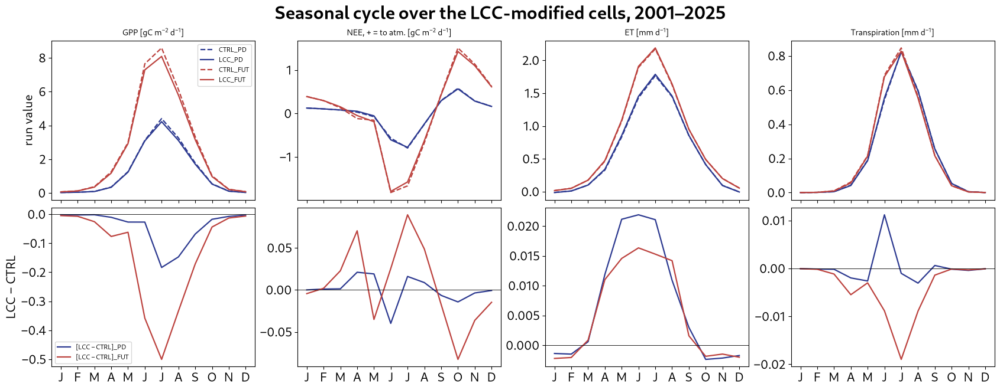

In [6]:
SEAS = [("BIOGEOCHEM", "GPP", 86400, "GPP [gC m$^{-2}$ d$^{-1}$]"),
        ("BIOGEOCHEM", "NEE", 86400, "NEE, + = to atm. [gC m$^{-2}$ d$^{-1}$]"),
        ("ET", "QFLX_EVAP_TOT", 86400, "ET [mm d$^{-1}$]"),
        ("ET", "QVEGT", 86400, "Transpiration [mm d$^{-1}$]")]
RUNS = {"CTRL_PD": (pal.NAVY, "--"), "LCC_PD": (pal.NAVY, "-"), "CTRL_FUT": (pal.RED, "--"), "LCC_FUT": (pal.RED, "-")}
w = W.where(REGIONS["modified cells"], 0.0)

def clim(alias, cls, var, scale):
    ds = fm.open_class(alias, cls, START_YEAR, END_YEAR, "lnd")
    s = ds[var].weighted(w).mean(("lat", "lon")) * scale
    return s.groupby("time.month").mean()

fig, axes = plt.subplots(2, len(SEAS), figsize=(4.2 * len(SEAS), 6.5), sharex=True, constrained_layout=True)
seas_rows = []
for j, (cls, var, scale, ylabel) in enumerate(SEAS):
    c = {a: clim(a, cls, var, scale) for a in RUNS}
    for a, (col, ls) in RUNS.items():
        axes[0, j].plot(c[a].month, c[a], color=col, ls=ls, lw=1.6, label=a)
    for per, col in (("PD", pal.NAVY), ("FUT", pal.RED)):
        d = c[f"LCC_{per}"] - c[f"CTRL_{per}"]
        axes[1, j].plot(d.month, d, color=col, lw=1.6, label=f"[LCC − CTRL]_{per}")
        seas_rows += [dict(variable=var, period=per, month=int(m), diff=float(x)) for m, x in zip(d.month.values, d.values)]
    axes[0, j].set_title(ylabel, fontsize=10)
    axes[1, j].axhline(0, color="black", lw=0.6)
    axes[1, j].set_xticks(range(1, 13), list("JFMAMJJASOND"))
axes[0, 0].legend(fontsize=8); axes[1, 0].legend(fontsize=8)
axes[0, 0].set_ylabel("run value"); axes[1, 0].set_ylabel("LCC − CTRL")
fig.suptitle(f"Seasonal cycle over the LCC-modified cells, {START_YEAR}–{END_YEAR}", fontweight="bold")
(FIGDIR / "interactive").mkdir(parents=True, exist_ok=True)
path = FIGDIR / "interactive" / f"seasonal_cycle_carbon_et_modified_{START_YEAR}_{END_YEAR}.png"
fig.savefig(path, dpi=200, bbox_inches="tight"); print("Saved", path)
pd.DataFrame(seas_rows).to_csv(TABDIR / f"seasonal_cycle_lcc_minus_ctrl_modified_{START_YEAR}_{END_YEAR}.csv", index=False)
plt.show(); plt.close(fig)